# Devoir maison 2 — carnets J3 et J4

> **À rendre avant la séance 5** — comme tout devoir, avant la première séance de la semaine
> suivante. Ce devoir porte sur **J3** (comparer sans se mentir, puis ce qu’on fait des défauts
> trouvés) et sur **J4** (la mesure, et la révélation). Il se fait **seul**, à la maison, et il se
> rend.

**Ce qu’on rend :** ce carnet, rempli, déposé dans votre **dépôt GitHub personnel** avec la
déclaration d’usage de l’IA (`declaration_DM2.md`). **Le journal de nettoyage** et **le tableau à
quatre colonnes** en sont les pièces principales.

**Pourquoi ce devoir :** chaque question demande une mesure que **vous** produisez — pas une
lecture. Si vous n’avez pas compris, ça se verra tout de suite ; c’est fait pour ça.

**Ce qui est lu.** Ce qui est lu ici : **les tableaux** et le code. Les tableaux : le tableau à quatre colonnes, le
journal de nettoyage, vos métriques. Le code : là où il produit un chiffre. **Ce dépôt est
relevé** : il est lu. Les **sept devoirs** comptent ensemble pour **10 % de la
note**. C'est la composante « exercices et devoirs » du cours (25 %, avec E1, E2, E3).
**Il n’y a pas d’oral sur les devoirs** : l’oral individuel, en fin de parcours, porte sur
l’ensemble de votre travail.

**Trois mots, pour être sûr :**

- **la baseline** — le modèle bête qu’il faut battre : la réponse constante, ou la règle du délai en
  place. Un score ne se lit jamais seul.
- **la barre de bruit** — de combien un score bouge tout seul ; en dessous, un écart n’est pas un
  gain.
- **le coût et le seuil** — ce que le métier paie pour chaque erreur, et le niveau de probabilité
  au-delà duquel on alerte.

---

## Comment ça marche

1. La partie **« Mise en place »** est **fournie** : exécutez-la, ne la modifiez pas. C’est elle
   qui lit les données, construit la table, mesure les baselines, la matrice et le coût — sans
   elle, aucune question ne peut tourner.
2. Chaque **question** porte sa consigne, un squelette et des **contrôles de forme**. Ils
   vérifient la forme de votre réponse : un pourcentage, une dimension, une cohérence avec
   vos autres réponses). Ils ne donnent **jamais** la réponse, et ils se taisent tant que vous
   n’avez pas écrit.
3. Une réponse se **chiffre** ou s’**écrit** — jamais « ça a marché ». **Deux** questions demandent
   d’**annoncer ce que vous attendez avant de mesurer** : c’est volontaire.
4. **Votre échantillon personnel** : dans la mise en place, remplacez `MON_IDENTIFIANT` par votre
   pseudo GitHub. Deux questions (Q9, Q10) se calculent **sur votre échantillon** : sans cela, vos
   chiffres sont ceux de tout le monde, et votre copie se recopie d’un voisin.
5. **Cœur** et **approfondissement** se rendent dans le **même dépôt**. La
   différence ne porte pas sur la note : elle dit où porter votre effort.
6. À la fin : les **trois tableaux**, puis le **dépôt**.

> **Ce qui est évalué, et ce qui se lit.** Trois objets traversent tout le cours, et on vous
> interrogera dessus — en devoir, au partiel, à l’oral. Le premier est la fonction `predict` :
> l’interface que le professeur appelle sur une table brute. Le deuxième est le **tableau d’essais** :
> ce que vous avez annoncé, essayé, mesuré. Le troisième est le **journal de nettoyage** : chaque
> décision, son choix, son effet mesuré. Ce qu’ils **retournent** est ce qu’on vous demandera de
> défendre — et votre projet s’appuiera dessus.


> **Version corrigée pour Kaggle.** Dans Kaggle, ouvrez ce notebook, utilisez **Add Input** pour joindre le jeu de données du cours contenant `train.csv` et `test.csv`, puis exécutez **Run All**. Le code recherche automatiquement le dossier qui contient les deux fichiers. Avant l'exécution, remplacez `MON_IDENTIFIANT` par votre pseudo GitHub. Les résultats chiffrés sont calculés à partir des fichiers réellement chargés : aucun chiffre de démonstration n'est inventé.


## Consignes pratiques avant de rendre

- Exécuter le carnet **de haut en bas**, dans l'environnement Kaggle où `train.csv` et `test.csv` sont disponibles.
- Dans la cellule « Votre échantillon personnel », remplacer `MON_IDENTIFIANT` par votre propre pseudo GitHub avant d'exécuter cette cellule.
- Les résultats chiffrés sont calculés à l'exécution sur les données réelles : ne pas recopier des chiffres provenant d'une autre personne.
- Vérifier les sorties et les contrôles de chaque question. Les contrôles vérifient surtout la forme et la cohérence des livrables ; ils ne garantissent pas à eux seuls la qualité scientifique de l'analyse.
- Le devoir demande une déclaration d'usage de l'IA (`declaration_DM2.md`) : la compléter honnêtement si une aide a été utilisée.

## Mise en place (fournie)

Exécutez cette partie **de haut en bas**, sans rien y modifier. Elle reprend la chaîne des
carnets : les données, la table, les baselines et la barre, la matrice de confusion, le
coût métier.

Les `random_state=0` sont la **graine du tirage au sort** (expliquée en
J1 §5). Le même nombre redonne le même découpage, donc la même mesure.


### Les outils


In [32]:
# les outils
# Aucun import en bloc au début : chaque module entre dans le carnet au moment de son premier
# usage. On voit ainsi à quoi il sert, au lieu de le deviner dans une liste.

# `display` : un tableau s'affiche proprement dans un carnet, et reste lisible ailleurs.
# C'est par `display` qu'on montre TOUTES les tables de ce carnet — jamais un print de texte.
try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


### Les données


In [33]:
import os
import pandas as pd

import os

def _trouver_dossier(racines):
    """Trouve le dossier qui contient ensemble train.csv et test.csv."""
    for racine in racines:
        if not os.path.isdir(racine):
            continue
        for chemin, _, fichiers in os.walk(racine):
            noms = set(fichiers)
            if {"train.csv", "test.csv"}.issubset(noms):
                return chemin
    return None

# Dans Kaggle, les fichiers joints avec « Add Input » se trouvent sous /kaggle/input.
# Si les données sont ailleurs, indiquez leur dossier dans DM2_DATA_DIR.
DOSSIER = os.environ.get("DM2_DATA_DIR") or _trouver_dossier(
    ["/kaggle/input", "/kaggle/working", "/mnt/data", "."]
)
if DOSSIER is None:
    raise FileNotFoundError(
        "Données introuvables. Dans Kaggle, cliquez sur Add Input et joignez le jeu "
        "du cours contenant train.csv et test.csv. Les deux fichiers doivent être dans "
        "le même dossier. Vous pouvez aussi définir DM2_DATA_DIR vers ce dossier."
    )
print("Dossier des données :", DOSSIER)

Dossier des données : /kaggle/input/competitions/rappels-et-sur-réservation-des-créneaux


In [34]:
train = pd.read_csv(os.path.join(DOSSIER, "train.csv"), low_memory=False)
test = pd.read_csv(os.path.join(DOSSIER, "test.csv"), low_memory=False)

ID, CIBLE = "ligne_id", "patient_absent"

# Contrôles du contrat des fichiers : ils évitent de poursuivre avec un mauvais jeu de données.
colonnes_requises_train = {ID, CIBLE}
colonnes_requises_test = {ID}
assert colonnes_requises_train.issubset(train.columns), (
    f"train.csv doit contenir {colonnes_requises_train}. Colonnes reçues : {list(train.columns)}"
)
assert colonnes_requises_test.issubset(test.columns), (
    f"test.csv doit contenir la colonne {ID}."
)
assert train[CIBLE].dropna().isin([0, 1]).all(), (
    f"{CIBLE} doit être codée avec 0 et 1."
)
assert train[CIBLE].notna().all(), "La cible contient des valeurs manquantes."
print("train :", train.shape, "| test :", test.shape)
display(train.head())

train : (149894, 39) | test : (63721, 38)


,dossier_id,ligne_id,patient_id,clinique,district,age,sexe,quartier,assurance,hypertension,...,indice_risque_externe,indice_meteo_jour,zone_clinique,tournee_jour,cout_acte,age_mois,score_territorial,canal_prise,taux_absence_passe,patient_absent
0,DOS-0127912,127913,P070425,C02,D3,53,F,Q04,privée,0,...,86.64,35,urbaine,T00000,10.4,636,-1.1621,guichet,0.0,1
1,DOS-0002883,2884,P109083,C36,D6,38,F,Q01,mutuelle,0,...,40.91,37,urbaine,T00002,5.3,456,-0.0963,guichet,0.0,0
2,DOS-0098561,98562,P036240,C43,D5,35,M,Q52,publique,1,...,28.34,82,urbaine,T00004,13.5,420,0.7951,en ligne,0.0,0
3,DOS-0133156,133157,P033484,C10,D2,36,M,Q07,aucune,0,...,55.91,76,urbaine,T00005,20.4,432,0.3788,guichet,0.0,0
4,DOS-0055744,55745,P035934,C28,D6,32,M,Q02,aucune,0,...,29.68,65,urbaine,T00006,8.8,384,1.2562,téléphone,0.0,0


### La table de travail


In [35]:
A_ECARTER = [ID, "dossier_id", "patient_id", "duree_consultation", "constantes_relevees",
             "motif_absence", "date_prise", "date_rdv", "taille_cm", "date_naissance",
             "canal_prise"]

def matrice(cols):
    """Construit les variables à partir des colonnes autorisées."""
    X_local = cols.drop(
        columns=[c for c in A_ECARTER + [CIBLE] if c in cols.columns]
    ).copy()
    cat = [c for c in X_local.columns
           if not pd.api.types.is_numeric_dtype(X_local[c])]
    trop_fin = [c for c in cat if X_local[c].nunique(dropna=True) > 255]
    X_local = X_local.drop(columns=trop_fin)
    cat = [c for c in cat if c not in trop_fin]
    for c in cat:
        X_local[c] = X_local[c].fillna("").astype("category")
    return X_local, cat, trop_fin

# Le schéma est appris une seule fois sur train.
X, CAT, TROP_FIN = matrice(train)

# Le test reprend exactement les colonnes et types appris sur train.
colonnes_test_absentes = [c for c in X.columns if c not in test.columns]
if colonnes_test_absentes:
    raise ValueError(
        "Colonnes de prédicteurs absentes de test.csv : "
        + ", ".join(colonnes_test_absentes[:20])
    )
Xt = test.loc[:, X.columns].copy()
for c in CAT:
    Xt[c] = Xt[c].fillna("").astype("category").cat.set_categories(
        X[c].cat.categories
    )
for c in X.columns:
    if c not in CAT and not pd.api.types.is_numeric_dtype(Xt[c]):
        raise TypeError(f"La colonne numérique {c!r} de test.csv n'est pas numérique.")

print("Variables conservées :", X.shape[1])
print("Variables catégorielles :", CAT)
print("Catégories trop nombreuses écartées :", TROP_FIN)

Variables conservées : 26
Variables catégorielles : ['clinique', 'district', 'sexe', 'quartier', 'assurance', 'rappel_envoye', 'zone_clinique']
Catégories trop nombreuses écartées : ['tournee_jour']


### La cible, et la référence


In [36]:
repartition = pd.DataFrame({"lignes": [len(train), int(train[CIBLE].sum())],
                            "part (%)": [100.0, round(100 * train[CIBLE].mean(), 2)]},
                           index=["toutes", "absents"])

reference = 100 * max(train[CIBLE].mean(), 1 - train[CIBLE].mean())


In [37]:
# `y` entre ici ; la référence a déjà été calculée avec la distribution ci-dessus —
y = train[CIBLE]


### Le découpage, le modèle, et les baselines


In [38]:
import numpy as np

# Découpage unique : les mêmes lignes servent à comparer tous les modèles.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)

# Référence : prédire la classe majoritaire pour tout le monde.
constante = 100 * max(yval.mean(), 1 - yval.mean())

# Baseline du délai : le seuil est choisi uniquement sur l'apprentissage.
delai_max = int(Xtr["delai_jours"].max())
seuils_delai = [s for s in (0, 1, 3, 7, 14, 30) if s < delai_max]
if not seuils_delai:
    seuils_delai = [delai_max - 1]
taux_par_seuil = {
    s: float(((Xtr["delai_jours"] > s).astype(int) == ytr).mean())
    for s in seuils_delai
}
seuil_appris = max(taux_par_seuil, key=taux_par_seuil.get)
regle = (Xval["delai_jours"] > seuil_appris).astype(int)
silence = np.zeros(len(yval), dtype=int)

# Version numérique pour les modèles qui ne lisent pas les catégories pandas.
X_n = pd.get_dummies(X, columns=CAT).fillna(0)
Xtr_n, Xval_n = X_n.loc[Xtr.index], X_n.loc[Xval.index]

lineaire = LogisticRegression(
    solver="newton-cholesky", max_iter=1000
).fit(Xtr_n, ytr)

modele = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr)

# Barre d'incertitude approximative sur l'exactitude de la référence.
barre = 100 * ((constante / 100) * (1 - constante / 100) / len(yval)) ** 0.5

baselines = pd.DataFrame([
    {"baseline": "toujours présent", "exactitude (%)": round(constante, 2)},
    {"baseline": f"règle du délai (> {seuil_appris} jours)",
     "exactitude (%)": round(100 * (regle == yval).mean(), 2)},
    {"baseline": "handicap = 1 annonce une absence",
     "exactitude (%)": round(100 * ((Xval["handicap"] == 1).astype(int) == yval).mean(), 2)},
    {"baseline": "régression logistique",
     "exactitude (%)": round(100 * lineaire.score(Xval_n, yval), 2)},
    {"baseline": "HistGradientBoosting",
     "exactitude (%)": round(100 * modele.score(Xval, yval), 2)},
])
display(baselines)
print(f"Référence constante : {constante:.2f} % ; barre : {barre:.3f} point.")

,baseline,exactitude (%)
0,toujours présent,81.75
1,règle du délai (> 30 jours),79.92
2,handicap = 1 annonce une absence,80.49
3,régression logistique,82.21
4,HistGradientBoosting,82.51


Référence constante : 81.75 % ; barre : 0.223 point.


### La matrice de confusion, et les probabilités


In [39]:
# Les quatre cases, dans le même ordre que le cours.
import numpy as np
from sklearn.metrics import confusion_matrix

predit = modele.predict(Xval)
VN, FP, FN, VP = confusion_matrix(yval, predit, labels=[0, 1]).ravel()
assert VP + FP + FN + VN == len(yval)

# La probabilité de la classe 1 (= patient absent) permet de changer le seuil.
probabilites = modele.predict_proba(Xval)[:, 1]
print(f"VP={VP} | FP={FP} | FN={FN} | VN={VN}")

VP=580 | FP=353 | FN=4891 | VN=24155


### Le coût métier


In [40]:
# Coûts métier fixés par l'énoncé : une fausse alerte vaut 25, une absence manquée 100.
COUT_FP, COUT_FN = 25, 100

def cout(decision, verite=None):
    """Coût total = 25 × FP + 100 × FN."""
    decision = np.asarray(decision, dtype=int)
    verite = np.asarray(yval if verite is None else verite, dtype=int)
    faux_positifs = int(((decision == 1) & (verite == 0)).sum())
    faux_negatifs = int(((decision == 0) & (verite == 1)).sum())
    return COUT_FP * faux_positifs + COUT_FN * faux_negatifs

seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)
print(f"Seuil théorique si les probabilités sont calibrées : {seuil_theorique:.2f}")

Seuil théorique si les probabilités sont calibrées : 0.20


### Les outils du nettoyage


In [41]:
# Mesure comparable : même découpage, même algorithme, même graine.
def score_de(Xe, ye=None):
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(
        Xe, ye, test_size=0.2, stratify=ye, random_state=0
    )
    m = HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m)
    return 100 * m.score(Xval_m, yval_m)

def score_sans_lignes(masque_a_garder):
    """Retire les lignes seulement de l'apprentissage ; Xval reste inchangé."""
    garde = masque_a_garder.loc[Xtr.index].astype(bool)
    m = HistGradientBoostingClassifier(random_state=0).fit(
        Xtr.loc[garde], ytr.loc[garde]
    )
    return 100 * m.score(Xval, yval)

In [42]:
# les colonnes inutiles, et la raison de chacune
raisons = {
    "zone_clinique": "une seule valeur sur toute la table",
    "indice_meteo_jour": "du bruit pur",
    "score_territorial": "42 052 valeurs, aucune raison de croire qu’elles disent quelque chose",
    "age_mois": "age_mois ÷ 12 = age — sur 100 % des lignes (mesuré en J1, 2.6)",
    "cout_acte": "montant_acte = 13,68 × cout_acte, rapport constant (mesuré en J1, 2.6)",
}
inutiles = [c for c in raisons if c in X.columns]


In [43]:
# le journal de nettoyage — ce qui est lu n’est pas le score, c’est le tableau
JOURNAL = []

def journal(decision, choix, raison, effet):
    """Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
       en points — avec la comparaison au double de la barre, qui dit si l’effet compte."""
    JOURNAL.append({"décision": decision, "choix": choix, "raison (sans le score)": raison,
                    "effet mesuré": round(effet, 2),
                    "> double de la barre ?": "oui" if abs(effet) > 2 * barre else "non"})
    display(pd.DataFrame(JOURNAL))


### Le pipeline, et le fichier à envoyer


In [44]:
# Pipeline final : préparation, modèle et seuil métier appris sans toucher au jeu de contrôle.
from sklearn.model_selection import cross_val_predict

seuils_deploiement = np.round(np.arange(0.04, 0.96, 0.02), 2)
probas_cv = cross_val_predict(
    HistGradientBoostingClassifier(random_state=0),
    Xtr, ytr, cv=5, method="predict_proba"
)[:, 1]
couts_cv = [
    cout((probas_cv >= s).astype(int), verite=ytr)
    for s in seuils_deploiement
]
seuil_deploiement = float(seuils_deploiement[int(np.argmin(couts_cv))])

def nettoyer(brut):
    """Applique les colonnes et types appris sur train ; refuse les entrées cassées."""
    colonnes_absentes = [c for c in X.columns if c not in brut.columns]
    if colonnes_absentes:
        raise ValueError(
            "Colonnes attendues absentes : " + ", ".join(colonnes_absentes[:10])
        )

    d = brut.loc[:, X.columns].copy()
    for c in CAT:
        d[c] = d[c].fillna("").astype("category").cat.set_categories(
            X[c].cat.categories
        )

    colonnes_numeriques = [c for c in X.columns if c not in CAT]
    for c in colonnes_numeriques:
        if not pd.api.types.is_numeric_dtype(d[c]):
            raise TypeError(
                f"La colonne numérique {c!r} a reçu le type {d[c].dtype!s}."
            )
    return d

def pipeline(brut):
    """Retourne 0/1 : 1 = absence annoncée, au seuil choisi par validation croisée."""
    proba = modele_final.predict_proba(nettoyer(brut))[:, 1]
    return (proba >= seuil_deploiement).astype(int)

X_propre = nettoyer(train)
modele_final = HistGradientBoostingClassifier(random_state=0).fit(X_propre, y)

soumission = pd.DataFrame({
    ID: test[ID].to_numpy(),
    CIBLE: pipeline(test)
})
DOSSIER_SORTIE = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
CHEMIN_SOUMISSION = os.path.join(DOSSIER_SORTIE, "submission.csv")
soumission.to_csv(CHEMIN_SOUMISSION, index=False)

assert len(soumission) == len(test)
assert list(soumission.columns) == [ID, CIBLE]
assert soumission[CIBLE].isin([0, 1]).all()
print(f"Seuil de déploiement appris par validation croisée : {seuil_deploiement:.2f}")
print("Fichier créé :", CHEMIN_SOUMISSION, "| dimensions :", soumission.shape)
display(soumission.head())

Seuil de déploiement appris par validation croisée : 0.18
Fichier créé : /kaggle/working/submission.csv | dimensions : (63721, 2)


,ligne_id,patient_absent
0,44088,0
1,120507,0
2,46612,0
3,3933,1
4,144527,0


### Le rituel : annoncer avant de mesurer


In [45]:
# l'horloge entre ici : c'est elle qui rend une prédiction vérifiable
from datetime import datetime

ESSAIS = []
PREDICTIONS = []

def prevoir(essai, attendu, raison):
    """Écrit ce que vous attendez AVANT de mesurer — horodaté.
       `noter(...)` refuse ensuite tout essai sans prédiction : l'ordre n'est pas demandé, il est
       appliqué. Ce que cette fonction garantit, exactement : une prédiction EXISTAIT avant que la
       ligne du tableau soit écrite. Elle ne date pas la mesure — le score lui arrive déjà calculé.
       Pour la garantie complète, mesurez dans `essai(...)`, qui date la mesure lui-même."""
    PREDICTIONS[:] = [p for p in PREDICTIONS if p["essai"] != essai]
    PREDICTIONS.append({"essai": essai, "attendu": attendu, "raison": raison,
                        "écrit à": datetime.now().strftime("%H:%M:%S")})
    display(pd.DataFrame(PREDICTIONS))

def essai(nom, mesure, changement="", attendu=""):
    """Le chemin STRICT : la mesure est prise ICI, donc l'ordre (prédiction puis mesure) est prouvé.
       `mesure` est une fonction sans argument qui rend le score, par exemple
       `lambda: modele.score(Xval, yval)`. Refuse de mesurer sans prédiction."""
    prevu = [p for p in PREDICTIONS if p["essai"] == nom]
    if not prevu:
        print(f"refusé : aucune prédiction pour « {nom} ». Écrivez prevoir(...) d'abord.")
        return None
    score = 100 * mesure()
    noter(nom, changement or "voir la question", attendu or prevu[0]["attendu"], score)
    return score

def noter(hypothese, changement, attendu, score):
    """Ajoute une ligne au tableau. `attendu` : un signe et une raison, jamais une valeur.
       Ré-exécuter une cellule REMPLACE la ligne de même `hypothèse` : elle ne la double pas.

       REFUSE d'enregistrer un essai non annoncé — c'est la règle du cours, appliquée.
       Ce qu'elle garantit, et rien de plus : une prédiction existait AVANT que cette ligne soit
       écrite. Elle ne date pas la mesure — d'où `essai(...)` pour la garantie complète."""
    prevu = [p for p in PREDICTIONS if p["essai"] == hypothese]
    if not prevu:
        print(f"  refusé : aucune prédiction pour « {hypothese} ».")
        print("  Écrivez prevoir(...) d'abord — l'ordre est vérifié, pas seulement demandé.")
        return
    ligne = {"hypothèse": hypothese, "changement": changement,
             "attendu": attendu, "mesuré": round(score, 2),
             "prédiction écrite avant ?": "oui, à " + prevu[0]["écrit à"]}
    ESSAIS[:] = [e for e in ESSAIS if e["hypothèse"] != hypothese] + [ligne]
    display(pd.DataFrame(ESSAIS))


### Votre échantillon personnel — **à personnaliser**

Deux questions se calculent sur un **échantillon qui n’appartient qu’à vous** : il est tiré de
votre identifiant. Il fait la moitié du jeu de contrôle. Remplacez la ligne `MON_IDENTIFIANT`
par votre pseudo GitHub, puis exécutez la cellule : elle affiche la taille de votre échantillon et
sa graine. Le reste de la mise en place, lui, ne se modifie pas.


In [46]:
# Échantillon personnel : le pseudo GitHub détermine la graine de tirage.
import zlib

MON_IDENTIFIANT = "REMPLACER_PAR_VOTRE_PSEUDO_GITHUB"
if MON_IDENTIFIANT == "REMPLACER_PAR_VOTRE_PSEUDO_GITHUB":
    print("ATTENTION : remplacez MON_IDENTIFIANT par votre pseudo GitHub avant de rendre le devoir.")

graine_perso = zlib.crc32(MON_IDENTIFIANT.strip().lower().encode())
positions = Xval.sample(frac=0.5, random_state=graine_perso).index
ou = Xval.index.get_indexer(positions)
Xval_perso = Xval.loc[positions]
yval_perso = yval.loc[positions]
proba_perso = probabilites[ou]

print(
    f"Échantillon personnel : {len(positions)} lignes sur {len(Xval)} ; "
    f"graine = {graine_perso}."
)

ATTENTION : remplacez MON_IDENTIFIANT par votre pseudo GitHub avant de rendre le devoir.
Échantillon personnel : 14990 lignes sur 29979 ; graine = 1888934284.


### Les vérifications, et le tableau d’essais


In [47]:
def phrases(reponse):
    """Une réponse de prose peut arriver en liste, en Series ou en table : on la ramène à des phrases."""
    if hasattr(reponse, "to_dict"):
        return [str(v) for ligne in reponse.to_dict("records") for v in ligne.values()]
    return [str(p) for p in reponse]

VERIFICATIONS = []

def verifier(nom, condition, indice=''):
    """Contrôle silencieux : il ne dit jamais la valeur attendue."""
    VERIFICATIONS.append({'contrôle': nom, 'tient': bool(condition)})
    print(('  ok        ' if condition else '  À REVOIR  ') + nom
          + ('' if condition else '   ->   ' + indice))

def controle(nom, quoi, indice=''):
    """Contrôle de forme, posé dans la cellule de la question. Il ne compare jamais à une valeur
       attendue : un type, une plage, une dimension, ou une cohérence avec vos autres réponses.
       Tant que la réponse n’est pas écrite, il se tait."""
    try:
        ok = bool(quoi())
    except NameError:
        print(f'  (pas encore écrit)  {nom}')
        return
    except Exception as e:
        print(f'  REVOIR    {nom}   ->   {type(e).__name__} : {e}')
        return
    VERIFICATIONS.append({'contrôle': nom, 'tient': ok})
    print(('  ok        ' if ok else '  REVOIR    ') + nom + ('' if ok else '   ->   ' + indice))

# le tableau d'essais et son `noter` strict viennent de la mise en place (extraits de J1) :
# il refuse un essai non annoncé. Le devoir n'en redéfinit pas un second, plus permissif.


### La mise en place est-elle prête ?


In [48]:
# sept vérifications d'état — elles portent sur la mise en place, pas sur vos réponses
verifier('les données sont chargées', len(train) > 0)
verifier('la table de travail est construite', 'patient_absent' not in X.columns)
verifier('le découpage est fait, le modèle ajusté', len(probabilites) == len(yval))
verifier('les baselines sont mesurées', constante > 50 and barre > 0)
verifier('votre échantillon personnel est prêt', len(yval_perso) > 1000)
verifier('le pipeline tourne sur une table brute', len(pipeline(test.head(50))) == 50)
verifier('le fichier est écrit', os.path.exists('submission.csv'))


  ok        les données sont chargées
  ok        la table de travail est construite
  ok        le découpage est fait, le modèle ajusté
  ok        les baselines sont mesurées
  ok        votre échantillon personnel est prêt
  ok        le pipeline tourne sur une table brute
  ok        le fichier est écrit


## Les questions

**Douze questions : dix de cœur, deux d’approfondissement.** Elles suivent l’ordre des
carnets — J3 d’abord (comparer, puis nettoyer), J4 ensuite (la mesure). Pour chacune : lisez
la consigne, écrivez votre code (ou votre phrase) à l’emplacement prévu, et **exécutez la
cellule** — c’est l’exécution qui déclenche les contrôles.


### Question 1 — Une baseline de votre main, et sa place dans le tableau  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le carnet J3 a mesuré **ses** baselines. La vôtre doit être la vôtre.

**Consigne.**
  1. choisissez une colonne que **ni la réponse constante ni la règle du délai du carnet**
     (`delai_jours`) n'utilise. Écrivez la règle en une phrase : quel signal, quelle décision ;
  2. mesurez son exactitude sur le jeu de validation (`Xval`, `yval`) ;
  3. divisez son écart à `constante` — la réponse constante, **81,75 %** — par `barre` : combien
     d'erreurs-types cela fait-il ?

**Livrables.** `ma_regle` · `ma_baseline` · `mes_erreurs_types`.

**Critère de réussite.** Une règle qui **égale ou dépasse** la constante est un résultat — dites-le.
Un écart sous une barre n'est pas un gain.

*≈ 20 min.*


In [49]:
# Règle : si handicap vaut 1, annoncer une absence ; sinon annoncer une présence.
# Cette règle utilise une colonne autre que la cible et que delai_jours.

ma_regle = (
    "Si handicap = 1, je prédis une absence (1) ; "
    "sinon, je prédis une présence (0)."
)
prediction_handicap = (Xval["handicap"] == 1).astype(int)
ma_baseline = float(100 * (prediction_handicap == yval).mean())

# Écart signé : négatif = moins bon que la référence constante.
mes_erreurs_types = float((ma_baseline - constante) / barre)

print("Règle :", ma_regle)
print(f"Exactitude de la règle : {ma_baseline:.2f} %")
print(f"Référence constante : {constante:.2f} %")
print(f"Écart / barre : {mes_erreurs_types:+.2f} erreur(s)-type(s)")
if mes_erreurs_types < 0:
    print("Interprétation : cette règle fait moins bien que la réponse constante.")
elif mes_erreurs_types < 1:
    print("Interprétation : elle ne dépasse pas clairement le bruit de mesure.")
else:
    print("Interprétation : elle dépasse la référence de plus d'une barre.")

controle('la règle est écrite', lambda: len(ma_regle) > 40,
         'décrivez la colonne et la décision en une phrase')
controle('une exactitude en pourcentage', lambda: 0 < ma_baseline <= 100,
         'un pourcentage (0 à 100), pas une proportion')
controle('un écart exprimé en erreurs-types', lambda: abs(mes_erreurs_types) < 30,
         'divisez l’écart à la référence par la barre')

Règle : Si handicap = 1, je prédis une absence (1) ; sinon, je prédis une présence (0).
Exactitude de la règle : 80.49 %
Référence constante : 81.75 %
Écart / barre : -5.67 erreur(s)-type(s)
Interprétation : cette règle fait moins bien que la réponse constante.
  ok        la règle est écrite
  ok        une exactitude en pourcentage
  ok        un écart exprimé en erreurs-types


### Question 2 — Le classement affiché tient-il ?  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, douze variantes jugées sur 1 000 lignes affichées ne se retrouvaient pas sur
celles jamais montrées. L'**affichage** est l'échantillon sur lequel le classement se lit ; le reste, celui qu'on
ne regarde pas avant de mesurer.

**Consigne.**
  1. annoncez **avant** de mesurer : le premier de l’affichage sera-t-il aussi le premier des lignes jamais montrées ?
  2. pour cette question, mettez **4 000 lignes de côté dans `Xtr`, avant d’entraîner** : elles ne servent ni à
     l’apprentissage, ni au choix des réglages. Coupez-les en 1 000 pour l’affichage et 3 000 jamais
     montrées (`train_test_split`, `random_state=0`) ;
  3. faites varier **six** réglages de votre choix, chacun entraîné sur les lignes qui restent — et dites **ce qui varie** (le nombre
     d'itérations ? la profondeur ? les deux ?) ;
  4. mesurez. Le premier de l’affichage est la variante qui a le meilleur score sur les 1 000.
     Donnez son **rang** parmi les lignes jamais montrées (1 = premier).

**Livrables.** `mon_annonce` · `score_affiche_premier` · `score_jamais_montre_premier` · `rang_jamais_montre_premier`.

**Critère de réussite.** Un seul tirage ne prouve pas qu'« un classement tient » : il montre **ce**
tirage-là. Dites ce que vous pouvez conclure, et ce que vous ne pouvez pas.

*≈ 25 min.*


In [50]:
# On isole 4 000 lignes AVANT entraînement : 1 000 affichées, 3 000 cachées.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier

mon_annonce = (
    "Je pense que le premier sur les 1 000 lignes affichées peut perdre sa première place "
    "sur les 3 000 lignes cachées : le choix parmi plusieurs réglages peut s'adapter au hasard "
    "de l'échantillon affiché."
)

if len(Xtr) <= 4000:
    raise ValueError("La question 2 exige plus de 4 000 lignes dans Xtr.")

X_restant, X_reserve, y_restant, y_reserve = train_test_split(
    Xtr, ytr, test_size=4000, stratify=ytr, random_state=0
)
X_affiche, X_cache, y_affiche, y_cache = train_test_split(
    X_reserve, y_reserve, test_size=3000, stratify=y_reserve, random_state=0
)

# Six réglages réellement différents : itérations et nombre de feuilles changent.
reglages = [(30, 7), (50, 7), (30, 15), (50, 15), (70, 15), (50, 31)]
noms_modeles, scores_affiche, scores_cache = [], [], []

for max_iter, feuilles in reglages:
    candidat = HistGradientBoostingClassifier(
        max_iter=max_iter, max_leaf_nodes=feuilles,
        early_stopping=False, random_state=0
    )
    candidat.fit(X_restant, y_restant)
    noms_modeles.append(f"boost_iter{max_iter}_feuilles{feuilles}")
    scores_affiche.append(100 * candidat.score(X_affiche, y_affiche))
    scores_cache.append(100 * candidat.score(X_cache, y_cache))

indice_premier = int(np.argmax(scores_affiche))
score_affiche_premier = float(scores_affiche[indice_premier])
score_jamais_montre_premier = float(scores_cache[indice_premier])
rang_jamais_montre_premier = 1 + sum(
    s > score_jamais_montre_premier for s in scores_cache
)

display(pd.DataFrame({
    "réglage": noms_modeles,
    "score affiché (%)": np.round(scores_affiche, 2),
    "score jamais montré (%)": np.round(scores_cache, 2)
}))
print("Annonce :", mon_annonce)
print("Premier sur l'affichage :", noms_modeles[indice_premier])
print(f"Son score affiché : {score_affiche_premier:.2f} %")
print(f"Son score jamais montré : {score_jamais_montre_premier:.2f} %")
print(f"Son rang sur les 3 000 lignes cachées : {rang_jamais_montre_premier}/6")
print(
    "Conclusion : ce tirage montre la stabilité (ou l'instabilité) de ce classement, "
    "mais un seul tirage ne prouve pas qu'un classement sera toujours stable."
)

controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce) > 30,
         'annoncez ce que vous attendez, en une phrase')
controle('deux scores en pourcentage',
         lambda: 50 < score_affiche_premier <= 100 and 50 < score_jamais_montre_premier <= 100,
         'deux pourcentages, un par jeu')
controle('un rang entre 1 et 6', lambda: 1 <= rang_jamais_montre_premier <= 6,
         'donnez son rang parmi les six variantes')

,réglage,score affiché (%),score jamais montré (%)
0,boost_iter30_feuilles7,83.3,82.70
1,boost_iter50_feuilles7,83.2,82.70
2,boost_iter30_feuilles15,83.0,82.60
3,boost_iter50_feuilles15,82.8,82.63
4,boost_iter70_feuilles15,82.9,82.83
5,boost_iter50_feuilles31,82.9,82.53


Annonce : Je pense que le premier sur les 1 000 lignes affichées peut perdre sa première place sur les 3 000 lignes cachées : le choix parmi plusieurs réglages peut s'adapter au hasard de l'échantillon affiché.
Premier sur l'affichage : boost_iter30_feuilles7
Son score affiché : 83.30 %
Son score jamais montré : 82.70 %
Son rang sur les 3 000 lignes cachées : 2/6
Conclusion : ce tirage montre la stabilité (ou l'instabilité) de ce classement, mais un seul tirage ne prouve pas qu'un classement sera toujours stable.
  ok        une annonce est écrite avant la mesure
  ok        deux scores en pourcentage
  ok        un rang entre 1 et 6


### Question 3 — Deux modèles, un seul découpage  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, deux réglages comparés sur le même découpage différaient de **0,04 point**.

**Consigne.**
  1. entraînez **deux modèles de votre choix** sur `Xtr` — deux familles, ou deux réglages
     réellement différents. Attention : deux `max_iter` du même modèle boosté peuvent s'arrêter au
     **même arbre** (l'arrêt anticipé) et comparer un modèle à lui-même ;
  2. mesurez-les sur **le même** `Xval` ;
  3. écrivez l'écart en points, et dites s'il fait plus qu'**une** barre de bruit, plus que **deux**.

**Livrables.** `score_a` · `score_b` · `mon_verdict`.

**Critère de réussite.** La comparaison n'est honnête que si le découpage ne change pas entre les
deux mesures. Dites aussi, en une phrase, si les deux modèles sont vraiment deux modèles.

*≈ 20 min.*


In [51]:
# Régression logistique (linéaire) contre HistGradientBoosting (boosting).
score_a = float(100 * lineaire.score(Xval_n, yval))
score_b = float(100 * modele.score(Xval, yval))
ecart_modeles = abs(score_a - score_b)
nb_barres = ecart_modeles / barre

mon_verdict = (
    f"La régression logistique obtient {score_a:.2f} % et le boosting {score_b:.2f} %, "
    f"soit {ecart_modeles:.2f} point(s) d'écart, c'est-à-dire {nb_barres:.2f} barre(s). "
    + ("L'écart dépasse deux barres." if nb_barres > 2 else
       "L'écart dépasse une barre mais pas deux." if nb_barres > 1 else
       "L'écart ne dépasse pas une barre : il peut relever du bruit de mesure.")
    + " Les familles sont différentes et les deux scores sont mesurés sur le même Xval."
)
print(f"Modèle A — régression logistique : {score_a:.2f} %")
print(f"Modèle B — HistGradientBoosting : {score_b:.2f} %")
print(mon_verdict)

controle('deux scores en pourcentage',
         lambda: 50 < score_a <= 100 and 50 < score_b <= 100, 'deux pourcentages')
controle('un verdict écrit', lambda: len(mon_verdict) > 40,
         'dites si l’écart dépasse une barre, deux barres, ou aucune')

Modèle A — régression logistique : 82.21 %
Modèle B — HistGradientBoosting : 82.51 %
La régression logistique obtient 82.21 % et le boosting 82.51 %, soit 0.30 point(s) d'écart, c'est-à-dire 1.35 barre(s). L'écart dépasse une barre mais pas deux. Les familles sont différentes et les deux scores sont mesurés sur le même Xval.
  ok        deux scores en pourcentage
  ok        un verdict écrit


### Question 4 — Votre tableau à quatre colonnes  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le tableau à quatre colonnes du carnet J3, rempli avec **vos** lignes.

**Consigne.**
  1. construisez `mon_tableau` avec les quatre colonnes du carnet — `modèle · validation · affiché ·
     écart` — et **au moins deux** lignes de votre choix ;
  2. la colonne de l’**affichage** ne se remplit que pour un modèle **réellement envoyé**. Aucun
     envoi n’est demandé ici : reprenez le score affiché du cours (**81,81**) sur la ligne du
     modèle du cours, et laissez `None` ailleurs ;
  3. écrivez les trois phrases : *que ferais-je si je ne regardais que l’affichage ? qu'est-ce que
     cela me coûterait en vrai ? qu'est-ce qui me l'aurait dit ?*

**Livrables.** `mon_tableau` · `si_je_ne_voyais_que_l_affichage` · `ce_que_cela_couterait` ·
`ce_qui_me_l_aurait_dit`.

**Critère de réussite.** Une colonne vide n'est pas un oubli — c'est un modèle qui n'a pas été
envoyé. Un écart sain est petit ; un écart qui grandit dit que le modèle a été choisi pour plaire à l’affichage.

*≈ 20 min.*


In [52]:
# 81,81 % est le score affiché du cours ; seul le modèle du cours reçoit cette valeur.
score_constante = float(constante)
score_delai = float(100 * (regle == yval).mean())
score_lineaire = float(100 * lineaire.score(Xval_n, yval))
score_cours = float(100 * modele.score(Xval, yval))

mon_tableau = pd.DataFrame([
    {"modèle": "Réponse constante", "validation": round(score_constante, 2),
     "affiché": None, "écart": None},
    {"modèle": f"Règle du délai (> {seuil_appris} jours)",
     "validation": round(score_delai, 2), "affiché": None, "écart": None},
    {"modèle": "Modèle du cours — HistGradientBoosting",
     "validation": round(score_cours, 2), "affiché": 81.81,
     "écart": round(score_cours - 81.81, 2)},
    {"modèle": "Régression logistique", "validation": round(score_lineaire, 2),
     "affiché": None, "écart": None}
])

si_je_ne_voyais_que_l_affichage = (
    "Si je ne regardais que l'affichage, je retiendrais le modèle du cours, "
    "car son score affiché est de 81,81 %."
)
ce_que_cela_couterait = (
    f"Sur mon jeu de validation, le modèle obtient {score_cours:.2f} %, soit "
    f"{score_cours - 81.81:+.2f} point(s) par rapport à l'affichage. "
    "Choisir uniquement sur l'affichage peut donc surestimer la performance réelle."
)
ce_qui_me_l_aurait_dit = (
    "Une validation indépendante, non utilisée pour sélectionner les modèles, "
    "permet de mesurer la généralisation et de repérer un classement trop adapté à l'affichage."
)

display(mon_tableau)
print(si_je_ne_voyais_que_l_affichage)
print(ce_que_cela_couterait)
print(ce_qui_me_l_aurait_dit)

controle('un tableau d’au moins deux modèles', lambda: len(mon_tableau) >= 2,
         'deux lignes au moins')
controle('les trois phrases sont écrites',
         lambda: min(len(si_je_ne_voyais_que_l_affichage),
                     len(ce_que_cela_couterait), len(ce_qui_me_l_aurait_dit)) > 40,
         'trois phrases, chacune complète')

,modèle,validation,affiché,écart
0,Réponse constante,81.75,NaN,NaN
1,Règle du délai (> 30 jours),79.92,NaN,NaN
2,Modèle du cours — HistGradientBoosting,82.51,81.81,0.7
3,Régression logistique,82.21,NaN,NaN


Si je ne regardais que l'affichage, je retiendrais le modèle du cours, car son score affiché est de 81,81 %.
Sur mon jeu de validation, le modèle obtient 82.51 %, soit +0.70 point(s) par rapport à l'affichage. Choisir uniquement sur l'affichage peut donc surestimer la performance réelle.
Une validation indépendante, non utilisée pour sélectionner les modèles, permet de mesurer la généralisation et de repérer un classement trop adapté à l'affichage.
  ok        un tableau d’au moins deux modèles
  ok        les trois phrases sont écrites


### Question 5 — Le plafond : trois familles  ·  *carnet J3*  ·  *cœur*


**Contexte.** Trois familles qui ne partagent pas leur mécanisme plafonnent au même endroit : le
plafond n'est alors pas dans le modèle.

**Consigne.**
  1. annoncez **avant** : trois familles très différentes donneront-elles des scores très
     différents ?
  2. mesurez **trois familles **différentes** de votre choix** sur la même table, et le même découpage ;
  3. dites de combien de points la meilleure dépasse la moins bonne. Puis ce que cela implique :
     le plafond est-il dans le modèle, ou dans les données — **en exactitude** ?

**Livrables.** `mon_annonce_plafond` · `trois_scores` · `ma_conclusion_plafond`.

**Critère de réussite.** Toute conclusion doit venir avec l'écart **chiffré** entre la meilleure et la moins bonne — sinon c'est une impression.

*≈ 15 min.*


In [53]:
# Annonce formulée avant de lire les trois résultats.
mon_annonce_plafond = (
    "Je m'attends à des scores relativement proches : les trois familles utilisent les mêmes "
    "données et les mêmes étiquettes, même si leurs mécanismes d'apprentissage diffèrent."
)

from sklearn.tree import DecisionTreeClassifier

modele_q5_lineaire = lineaire
modele_q5_arbre = DecisionTreeClassifier(
    max_depth=8, min_samples_leaf=50, random_state=0
).fit(Xtr_n, ytr)
modele_q5_boost = modele

trois_scores = {
    "Régression logistique": float(100 * modele_q5_lineaire.score(Xval_n, yval)),
    "Arbre de décision": float(100 * modele_q5_arbre.score(Xval_n, yval)),
    "HistGradientBoosting": float(100 * modele_q5_boost.score(Xval, yval))
}
meilleur_score_q5 = max(trois_scores.values())
moins_bon_score_q5 = min(trois_scores.values())
ecart_q5 = meilleur_score_q5 - moins_bon_score_q5

ma_conclusion_plafond = (
    f"Les scores sont {trois_scores['Régression logistique']:.2f} %, "
    f"{trois_scores['Arbre de décision']:.2f} % et "
    f"{trois_scores['HistGradientBoosting']:.2f} %. L'écart maximal est "
    f"{ecart_q5:.2f} point(s). "
    + ("Les familles plafonnent près du même niveau : la limite semble davantage liée "
       "à l'information disponible et à la qualité des étiquettes qu'au choix du modèle."
       if ecart_q5 <= 2 * barre else
       "L'écart dépasse deux barres : le choix de la famille de modèle compte encore "
       "sur ce découpage.")
)
display(pd.DataFrame([
    {"famille": nom, "exactitude (%)": round(score, 2)}
    for nom, score in trois_scores.items()
]))
print("Annonce :", mon_annonce_plafond)
print(ma_conclusion_plafond)

controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce_plafond) > 30,
         'annoncez l’écart attendu entre trois familles')
controle('trois scores', lambda: len(trois_scores) == 3, 'trois familles, trois scores')
controle('la conclusion est argumentée', lambda: len(str(ma_conclusion_plafond)) > 40,
         'dites si le plafond est dans le modèle ou dans les données')

,famille,exactitude (%)
0,Régression logistique,82.21
1,Arbre de décision,82.43
2,HistGradientBoosting,82.51


Annonce : Je m'attends à des scores relativement proches : les trois familles utilisent les mêmes données et les mêmes étiquettes, même si leurs mécanismes d'apprentissage diffèrent.
Les scores sont 82.21 %, 82.43 % et 82.51 %. L'écart maximal est 0.30 point(s). Les familles plafonnent près du même niveau : la limite semble davantage liée à l'information disponible et à la qualité des étiquettes qu'au choix du modèle.
  ok        une annonce est écrite avant la mesure
  ok        trois scores
  ok        la conclusion est argumentée


### Question 6 — Le bruit d’étiquette  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le plafond peut aussi venir des **étiquettes** : personne n'annote parfaitement, et un
annotateur ne se trompe pas comme un modèle.

**Consigne.**
  1. retournez **15 %** des étiquettes d’**entraînement** (`ytr`), au hasard (`random_state=0`),
     et gardez **deux** modèles de la question 5 ;
  2. mesurez sur une validation **intacte** (`Xval`, `yval`) — sinon on mesure le bruit, pas ce
     qu'il coûte ;
  3. comparez chaque score à son score propre de la question 5, puis dites **quel** modèle est le
     plus abîmé, et de combien de points. Dites enfin ce que cela implique pour la **fiabilité des
     étiquettes** de ce jeu.

**Livrables.** `scores_bruites` · `modele_le_plus_abime` · `ma_conclusion_cible`.

**Critère de réussite.** Ce n'est pas « le score baisse-t-il ? » qui compte, mais **sur quel modèle** le
bruit mord — et pourquoi il est le plus touché.

*≈ 15 min.*


In [54]:
# Seules les étiquettes d'apprentissage sont inversées ; yval reste intact.
rng = np.random.RandomState(0)
ytr_bruite = ytr.copy()
positions_bruitees = rng.choice(
    len(ytr_bruite), size=int(round(0.15 * len(ytr_bruite))), replace=False
)
indices_bruites = ytr_bruite.index[positions_bruitees]
ytr_bruite.loc[indices_bruites] = 1 - ytr_bruite.loc[indices_bruites]

# Deux familles déjà évaluées à la question 5.
arbre_bruite = DecisionTreeClassifier(
    max_depth=8, min_samples_leaf=50, random_state=0
).fit(Xtr_n, ytr_bruite)
boost_bruite = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr_bruite)

scores_bruites = {
    "Arbre de décision": float(100 * arbre_bruite.score(Xval_n, yval)),
    "HistGradientBoosting": float(100 * boost_bruite.score(Xval, yval))
}
scores_originaux = {
    "Arbre de décision": trois_scores["Arbre de décision"],
    "HistGradientBoosting": trois_scores["HistGradientBoosting"]
}
baisses = {nom: scores_originaux[nom] - scores_bruites[nom]
           for nom in scores_bruites}
modele_plus_touche = max(baisses, key=baisses.get)
modele_le_plus_abime = (
    f"{modele_plus_touche}, avec une baisse de {baisses[modele_plus_touche]:.2f} point(s)"
)

ma_conclusion_cible = (
    f"Après inversion de 15 % des étiquettes, l'arbre passe de "
    f"{scores_originaux['Arbre de décision']:.2f} % à "
    f"{scores_bruites['Arbre de décision']:.2f} %, tandis que le boosting passe de "
    f"{scores_originaux['HistGradientBoosting']:.2f} % à "
    f"{scores_bruites['HistGradientBoosting']:.2f} %. "
    f"Le modèle le plus touché est {modele_plus_touche}. "
    "Cela montre que des étiquettes erronées peuvent apprendre au modèle de fausses associations ; "
    "la cible doit donc être vérifiée."
)
display(pd.DataFrame([
    {"modèle": nom, "score propre (%)": round(scores_originaux[nom], 2),
     "score bruité (%)": round(scores_bruites[nom], 2),
     "baisse (points)": round(baisses[nom], 2)}
    for nom in scores_bruites
]))
print(modele_le_plus_abime)
print(ma_conclusion_cible)

controle('deux scores après brouillage', lambda: len(scores_bruites) == 2,
         'deux modèles brouillés, deux scores')
controle('le modèle abîmé est nommé', lambda: len(str(modele_le_plus_abime)) > 10,
         'nommez le modèle que le bruit abîme le plus')
controle('la cible est interrogée', lambda: len(str(ma_conclusion_cible)) > 40,
         'écrivez ce que cela implique pour la fiabilité des étiquettes')

,modèle,score propre (%),score bruité (%),baisse (points)
0,Arbre de décision,82.43,82.13,0.31
1,HistGradientBoosting,82.51,82.46,0.05


Arbre de décision, avec une baisse de 0.31 point(s)
Après inversion de 15 % des étiquettes, l'arbre passe de 82.43 % à 82.13 %, tandis que le boosting passe de 82.51 % à 82.46 %. Le modèle le plus touché est Arbre de décision. Cela montre que des étiquettes erronées peuvent apprendre au modèle de fausses associations ; la cible doit donc être vérifiée.
  ok        deux scores après brouillage
  ok        le modèle abîmé est nommé
  ok        la cible est interrogée


### Question 7 — Un trou non informatif, un trou informatif  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, un trou peut ne rien dire (**non informatif**) ou porter de l’information
(**informatif**) — et le combler efface cette information. Le carnet a fait le geste sur deux
colonnes ; à vous de le refaire sur deux autres, de la **table brute**.

**Consigne.**
  1. choisissez **deux** colonnes à trous de `train` : une que vous pensez **non informative**,
     une **informative** ;
  2. pour chacune, comptez les deux groupes. Calculez le **taux d’absence du patient** (la
     cible) chez les lignes où la colonne **manque**, puis chez celles où elle est **remplie**. Ne
     comparez que des groupes d’**au moins 500 lignes** (la règle du cours) ;
  3. situez les deux taux par rapport au taux global (**18,25 %**) ;
  4. pour chacune, dites ce que vous en faites, et pourquoi.

**Livrables.** `mon_trou_a` · `mon_trou_b` — un dictionnaire par colonne, avec sa colonne, ses deux
effectifs et ses deux taux — puis `ma_decision_colonne`.

**Critère de réussite.** Si les deux taux d'une colonne sont **proches l’un de l’autre**, c'est un
résultat valable : dites-le. Un trou informatif n'est pas forcément une fuite — c'est l’**origine**
du trou qui décide.

*≈ 25 min.*


In [55]:
# On compare P(patient_absent=1 | valeur manquante) et P(patient_absent=1 | valeur remplie).
# Les deux groupes doivent contenir au moins 500 lignes. Les colonnes exclues du modèle
# pour fuite ou indisponibilité ne sont pas candidates.

colonnes_candidates = [
    c for c in X.columns
    if c in train.columns
    and train[c].isna().sum() >= 500
    and train[c].notna().sum() >= 500
]
comparaisons = []
for colonne in colonnes_candidates:
    manque = train[colonne].isna()
    n_manque, n_rempli = int(manque.sum()), int((~manque).sum())
    taux_manque = float(100 * train.loc[manque, CIBLE].mean())
    taux_rempli = float(100 * train.loc[~manque, CIBLE].mean())
    comparaisons.append({
        "colonne": colonne,
        "n_manque": n_manque,
        "n_rempli": n_rempli,
        "taux_manque": taux_manque,
        "taux_rempli": taux_rempli,
        "écart_absolu": abs(taux_manque - taux_rempli)
    })

if len(comparaisons) < 2:
    raise ValueError(
        "La question 7 exige deux colonnes candidates avec au moins 500 valeurs manquantes "
        "et 500 valeurs renseignées. Vérifiez le jeu train.csv."
    )

comparaisons = sorted(comparaisons, key=lambda d: d["écart_absolu"])
a, b = comparaisons[0], comparaisons[-1]

mon_trou_a = {
    "colonne": a["colonne"], "n_manque": a["n_manque"], "n_rempli": a["n_rempli"],
    "taux_manque": round(a["taux_manque"], 2), "taux_rempli": round(a["taux_rempli"], 2)
}
mon_trou_b = {
    "colonne": b["colonne"], "n_manque": b["n_manque"], "n_rempli": b["n_rempli"],
    "taux_manque": round(b["taux_manque"], 2), "taux_rempli": round(b["taux_rempli"], 2)
}
taux_global_absence = float(100 * train[CIBLE].mean())

ecart_a = abs(a["taux_manque"] - a["taux_rempli"])
ecart_b = abs(b["taux_manque"] - b["taux_rempli"])
lecture_b = (
    "l'écart signale un trou potentiellement informatif"
    if ecart_b >= 2
    else "les taux restent proches : ce trou ne paraît pas très informatif"
)
ma_decision_colonne = (
    f"Pour {a['colonne']}, le taux d'absence est de {a['taux_manque']:.2f} % quand la valeur "
    f"manque contre {a['taux_rempli']:.2f} % quand elle est renseignée, à comparer au taux "
    f"global de {taux_global_absence:.2f} % : les taux sont proches, donc le trou semble peu "
    f"informatif (écart {ecart_a:.2f} point). Pour {b['colonne']}, les taux sont "
    f"{b['taux_manque']:.2f} % et {b['taux_rempli']:.2f} % ; {lecture_b} "
    f"(écart {ecart_b:.2f} points), mais pas automatiquement une fuite. "
    "Je rechercherais l'origine du manque avant de choisir l'imputation ou l'indicateur."
)

display(pd.DataFrame(comparaisons).round(2))
print("Colonne A — taux proches :", mon_trou_a)
print("Colonne B — taux éloignés :", mon_trou_b)
print(f"Taux global d'absence : {taux_global_absence:.2f} %")
print(ma_decision_colonne)

controle('une colonne de la table brute est nommée (A)',
         lambda: mon_trou_a['colonne'] in train.columns,
         'le nom exact d’une colonne de `train`')
controle('une colonne de la table brute est nommée (B)',
         lambda: mon_trou_b['colonne'] in train.columns,
         'le nom exact d’une colonne de `train`')
controle('chaque groupe de A respecte le plancher du cours',
         lambda: min(mon_trou_a['n_manque'], mon_trou_a['n_rempli']) >= 500,
         'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('chaque groupe de B respecte le plancher du cours',
         lambda: min(mon_trou_b['n_manque'], mon_trou_b['n_rempli']) >= 500,
         'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('les deux taux de A sont des pourcentages',
         lambda: 0 <= mon_trou_a['taux_manque'] <= 100 and 0 <= mon_trou_a['taux_rempli'] <= 100,
         'deux pourcentages (0 à 100)')
controle('les deux taux de B sont des pourcentages',
         lambda: 0 <= mon_trou_b['taux_manque'] <= 100 and 0 <= mon_trou_b['taux_rempli'] <= 100,
         'deux pourcentages (0 à 100)')
controle('les deux colonnes sont différentes',
         lambda: mon_trou_a['colonne'] != mon_trou_b['colonne'],
         'une que vous pensez non informative, une informative')
controle('une décision est écrite', lambda: len(ma_decision_colonne) > 30,
         'que faites-vous de ces colonnes, et pourquoi')

,colonne,n_manque,n_rempli,taux_manque,taux_rempli,écart_absolu
0,solde_credit,8241,141653,18.00,18.27,0.27
1,rappel_envoye,99328,50566,13.13,28.32,15.19


Colonne A — taux proches : {'colonne': 'solde_credit', 'n_manque': 8241, 'n_rempli': 141653, 'taux_manque': 18.0, 'taux_rempli': 18.27}
Colonne B — taux éloignés : {'colonne': 'rappel_envoye', 'n_manque': 99328, 'n_rempli': 50566, 'taux_manque': 13.13, 'taux_rempli': 28.32}
Taux global d'absence : 18.25 %
Pour solde_credit, le taux d'absence est de 18.00 % quand la valeur manque contre 18.27 % quand elle est renseignée, à comparer au taux global de 18.25 % : les taux sont proches, donc le trou semble peu informatif (écart 0.27 point). Pour rappel_envoye, les taux sont 13.13 % et 28.32 % ; l'écart signale un trou potentiellement informatif (écart 15.19 points), mais pas automatiquement une fuite. Je rechercherais l'origine du manque avant de choisir l'imputation ou l'indicateur.
  ok        une colonne de la table brute est nommée (A)
  ok        une colonne de la table brute est nommée (B)
  ok        chaque groupe de A respecte le plancher du cours
  ok        chaque groupe de B respe

### Question 8 — Les décisions invisibles, et le journal  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Une décision qui ne gagne pas de point doit gagner **autre chose** — et ce quelque
chose s'écrit pour un audit. Le journal du carnet porte cinq colonnes : décision, choix, raison,
effet mesuré, et si l'effet dépasse le double de la barre.

**Consigne.**
  1. pour chaque décision de la mise en place (colonnes inutiles, codes non documentés, valeurs
     impossibles, doublons), appelez `journal(...)` — il est fourni. Notez l'effet **mesuré** ;
  2. pour chacune, la phrase qu'on donnerait à un audit — **sans invoquer le score ni l'exactitude** ;
  3. dites, pour une seule d'entre elles, ce que vous auriez fait autrement.

**Livrables.** `mes_effets` (une liste de nombres, un par décision) · `mes_raisons_d_audit` (une liste de phrases,
de la même longueur) · `mon_autre_choix`.

**Critère de réussite.** Une raison d'audit tient sans le score : elle dit **ce que la colonne est**,
pas ce qu'elle rapporte. Le journal est fourni : c'est **votre** remplissage qui est lu.

*≈ 20 min.*


In [56]:
# On mesure l'effet en points d'exactitude. Les raisons d'audit ne reposent pas sur le score.
score_reference_nettoyage = score_de(X, y)

# 1) Colonnes inutiles : constantes, bruit ou variables redondantes.
X_sans_inutiles = X.drop(columns=[c for c in inutiles if c in X.columns])
score_sans_inutiles = score_de(X_sans_inutiles, y)
effet_inutiles = score_sans_inutiles - score_reference_nettoyage

# 2) Codes d'assurance non documentés : comparer avec et sans la colonne.
if "code_assurance" in X.columns:
    score_sans_code = score_de(X.drop(columns=["code_assurance"]), y)
    effet_code = score_sans_code - score_reference_nettoyage
else:
    effet_code = 0.0

# 3) Âges impossibles : on retire les lignes concernées de l'apprentissage seulement.
if "age" in train.columns:
    masque_age_valide = train["age"] >= 0
    score_sans_ages_impossibles = score_sans_lignes(masque_age_valide)
    effet_age = score_sans_ages_impossibles - 100 * modele.score(Xval, yval)
    n_ages_impossibles = int((train["age"] < 0).sum())
else:
    effet_age, n_ages_impossibles = 0.0, 0

# 4) Doublons : on compare les lignes hors identifiant, comme dans J3.
masque_sans_doublons = ~train.drop(columns=[ID]).duplicated()
score_sans_doublons = score_sans_lignes(masque_sans_doublons)
effet_doublons = score_sans_doublons - 100 * modele.score(Xval, yval)
n_doublons = int((~masque_sans_doublons).sum())

JOURNAL.clear()
journal(
    "Colonnes inutiles", "Écarter les colonnes identifiées comme constantes, bruit ou redondantes.",
    "Une variable constante ne distingue pas les lignes ; une variable redondante répète une information déjà présente.",
    effet_inutiles
)
journal(
    "Code non documenté", "Garder code_assurance en signalant que les modalités ne sont pas documentées.",
    "Le dictionnaire disponible ne définit pas toutes les modalités, notamment les codes 7 et 9.",
    effet_code
)
journal(
    "Valeurs impossibles", f"Retirer les {n_ages_impossibles} lignes dont age est négatif de l'apprentissage.",
    "Un âge négatif ne correspond pas à une mesure valide ; il faut vérifier la source ou le corriger.",
    effet_age
)
journal(
    "Doublons", f"Retirer les {n_doublons} doublons exacts hors identifiant de l'apprentissage.",
    "Une même observation répétée peut donner un poids artificiel à cette observation pendant l'apprentissage.",
    effet_doublons
)

mes_effets = [
    round(effet_inutiles, 2), round(effet_code, 2),
    round(effet_age, 2), round(effet_doublons, 2)
]
mes_raisons_d_audit = [
    "Les variables retirées sont constantes, redondantes ou sans justification métier documentée.",
    "Le dictionnaire disponible ne définit pas toutes les modalités de code_assurance, notamment les codes 7 et 9.",
    "Un âge négatif est une valeur impossible et doit être vérifié auprès de la source des données.",
    "Les lignes dupliquées représentent plusieurs fois la même observation et peuvent biaiser l'apprentissage."
]
mon_autre_choix = (
    "Pour les âges négatifs, j'aurais pu remplacer -1 par une valeur manquante et ajouter un "
    "indicateur age_invalide, plutôt que supprimer les lignes : cela aurait conservé les autres "
    "informations utiles de ces patients."
)

print("Effets mesurés (points) :", mes_effets)
print("Raisons d'audit :", mes_raisons_d_audit)
print("Autre choix possible :", mon_autre_choix)

controle('au moins trois décisions', lambda: len(mes_effets) >= 3,
         'le carnet en montre plusieurs : listez-en au moins trois')
controle('une phrase par décision',
         lambda: len(phrases(mes_raisons_d_audit)) == len(mes_effets),
         'autant de phrases que de décisions')
controle('aucune phrase ne parle du score',
         lambda: not any('score' in p.lower() or 'exactitude' in p.lower()
                         for p in phrases(mes_raisons_d_audit)),
         'une raison d’audit ne s’appuie pas sur le score')
controle('un autre choix est écrit', lambda: len(str(mon_autre_choix)) > 30,
         'dites, pour une décision, ce que vous auriez fait autrement')

,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Écarter les colonnes identifiées comme constan...,Une variable constante ne distingue pas les li...,0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Écarter les colonnes identifiées comme constan...,Une variable constante ne distingue pas les li...,0.01,non
1,Code non documenté,Garder code_assurance en signalant que les mod...,Le dictionnaire disponible ne définit pas tout...,-0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Écarter les colonnes identifiées comme constan...,Une variable constante ne distingue pas les li...,0.01,non
1,Code non documenté,Garder code_assurance en signalant que les mod...,Le dictionnaire disponible ne définit pas tout...,-0.01,non
2,Valeurs impossibles,Retirer les 46 lignes dont age est négatif de ...,Un âge négatif ne correspond pas à une mesure ...,-0.00,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Écarter les colonnes identifiées comme constan...,Une variable constante ne distingue pas les li...,0.01,non
1,Code non documenté,Garder code_assurance en signalant que les mod...,Le dictionnaire disponible ne définit pas tout...,-0.01,non
2,Valeurs impossibles,Retirer les 46 lignes dont age est négatif de ...,Un âge négatif ne correspond pas à une mesure ...,-0.00,non
3,Doublons,Retirer les 0 doublons exacts hors identifiant...,Une même observation répétée peut donner un po...,0.00,non


Effets mesurés (points) : [0.01, -0.01, -0.0, 0.0]
Raisons d'audit : ['Les variables retirées sont constantes, redondantes ou sans justification métier documentée.', 'Le dictionnaire disponible ne définit pas toutes les modalités de code_assurance, notamment les codes 7 et 9.', 'Un âge négatif est une valeur impossible et doit être vérifié auprès de la source des données.', "Les lignes dupliquées représentent plusieurs fois la même observation et peuvent biaiser l'apprentissage."]
Autre choix possible : Pour les âges négatifs, j'aurais pu remplacer -1 par une valeur manquante et ajouter un indicateur age_invalide, plutôt que supprimer les lignes : cela aurait conservé les autres informations utiles de ces patients.
  ok        au moins trois décisions
  ok        une phrase par décision
  ok        aucune phrase ne parle du score
  ok        un autre choix est écrit


### Question 9 — Le pipeline, et sa solidité  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Le pipeline va de la table brute à la prédiction. Il est solide — jusqu'à ce qu'on le
casse. Vous allez le casser deux fois, et décrire ce qui se passe à chaque fois.

**Consigne.**
  1. vérifiez que `submission.csv` a exactement autant de lignes que `test.csv` ;
  2. cassez le pipeline deux fois. D’abord sur une copie de `test` dont une colonne numérique a
     été convertie en **texte**. Ensuite sur une copie à laquelle vous **retirez** une colonne ;
  3. pour chaque sabotage, dites ce qui se passe — et ce qu'il faut donc vérifier avant de livrer.

**Livrables.** `lignes_du_fichier` · `lignes_test` · `sabotage_texte` · `sabotage_colonne_manquante` ·
`ce_quil_faut_verifier`.

**Critère de réussite.** « Ça a échoué » n'est pas un compte-rendu : décrivez ce que chaque cassure a produit, et ce qu'il faut donc vérifier avant de livrer.

*≈ 20 min.*


In [57]:
fichier_soumission = pd.read_csv(CHEMIN_SOUMISSION)
lignes_du_fichier = len(fichier_soumission)
lignes_test = len(test)

# Sabotage 1 : une colonne numérique devient du texte.
colonne_numerique = next(
    (c for c in X.columns if c not in CAT and pd.api.types.is_numeric_dtype(X[c])),
    None
)
if colonne_numerique is None:
    raise ValueError("Aucune colonne numérique disponible pour le test de sabotage.")
test_texte = test.head(100).copy()
test_texte[colonne_numerique] = test_texte[colonne_numerique].astype(str)
try:
    pipeline(test_texte)
    sabotage_texte = (
        f"Après conversion de {colonne_numerique} en texte, le pipeline a accepté les données. "
        "Ce résultat serait dangereux : il faut vérifier explicitement les types."
    )
except Exception as erreur:
    sabotage_texte = (
        f"La conversion de {colonne_numerique} en texte déclenche {type(erreur).__name__} : "
        f"{str(erreur)[:220]}. Le pipeline refuse donc un type différent de celui appris."
    )

# Sabotage 2 : une colonne attendue par le modèle disparaît.
test_sans_colonne = test.head(100).drop(columns=[colonne_numerique])
try:
    pipeline(test_sans_colonne)
    sabotage_colonne_manquante = (
        "Le pipeline a accepté une table à laquelle une colonne attendue a été retirée ; "
        "il faut renforcer la vérification du schéma."
    )
except Exception as erreur:
    sabotage_colonne_manquante = (
        f"Le retrait de {colonne_numerique} déclenche {type(erreur).__name__} : "
        f"{str(erreur)[:220]}. Le modèle exige le même ensemble de variables qu'à l'entraînement."
    )

ce_quil_faut_verifier = (
    "Avant de livrer, vérifier les noms et types des colonnes, les valeurs manquantes, "
    "l'ordre et le nombre de lignes, les valeurs 0/1 de la cible, ainsi que les deux colonnes "
    "ligne_id et patient_absent du fichier de soumission."
)

print("Lignes dans submission.csv :", lignes_du_fichier)
print("Lignes dans test.csv :", lignes_test)
print("Sabotage texte :", sabotage_texte)
print("Sabotage colonne manquante :", sabotage_colonne_manquante)
print("À vérifier :", ce_quil_faut_verifier)

controle('le fichier a la forme du test',
         lambda: lignes_du_fichier == lignes_test, 'autant de lignes que test.csv')
controle('deux sabotages décrits',
         lambda: min(len(sabotage_texte), len(sabotage_colonne_manquante)) > 30,
         'une phrase par sabotage : ce qui se passe, et pourquoi')
controle('la leçon est écrite', lambda: len(str(ce_quil_faut_verifier)) > 30,
         'dites ce qu’il faut vérifier avant de livrer')

Lignes dans submission.csv : 63721
Lignes dans test.csv : 63721
Sabotage texte : La conversion de age en texte déclenche TypeError : La colonne numérique 'age' a reçu le type object.. Le pipeline refuse donc un type différent de celui appris.
Sabotage colonne manquante : Le retrait de age déclenche ValueError : Colonnes attendues absentes : age. Le modèle exige le même ensemble de variables qu'à l'entraînement.
À vérifier : Avant de livrer, vérifier les noms et types des colonnes, les valeurs manquantes, l'ordre et le nombre de lignes, les valeurs 0/1 de la cible, ainsi que les deux colonnes ligne_id et patient_absent du fichier de soumission.
  ok        le fichier a la forme du test
  ok        deux sabotages décrits
  ok        la leçon est écrite


### Question 10 — Vos six métriques, et les deux aires  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le carnet a calculé sa matrice au **seuil par défaut**. Vous, vous changez le seuil —
et vous ajoutez la mesure qui ne dépend d'aucun seuil : les **aires**.

**Consigne.**
  1. recalculez la matrice de confusion à **un seuil de votre choix** (différent de 0,50), à partir
     de `proba_perso`. Travaillez sur **votre échantillon** (`Xval_perso`, `yval_perso`) ;
  2. recalculez les **six** métriques depuis **votre** matrice. Attention : la précision divise par
     le nombre d'alertes — si votre seuil n'alerte sur personne, elle n'existe pas (0/0) ;
  3. dites laquelle vous tromperait le plus, et pourquoi ;
  4. chiffrez les deux extrêmes (*n'alerte jamais* / *alerte toujours*) sur deux métriques au moins.
     Puis les **deux aires** (ROC et PR) sur votre échantillon — et leur rapport au taux de base.
  5. calculez la **log-loss** de votre modèle sur votre échantillon, et dites en une phrase ce
     qu’elle mesure que l’exactitude ne mesure pas.

**Livrables.** `mon_seuil` · `ma_matrice` · `mes_metriques` · `metrique_trompeuse` ·
`extreme_sans_alerte` · `extreme_toujours_alerte` · `aires_perso` · `ma_log_loss`.

**Critère de réussite.** Les deux aires n'ont de sens que **comparées au taux de base** : dites combien de fois chacune le dépasse.

*≈ 30 min.*


In [58]:
# Tous les calculs portent sur VOTRE échantillon personnel et le seuil n'est pas 0,50.
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

mon_seuil = 0.35
y_vrai = np.asarray(yval_perso, dtype=int)
p = np.asarray(proba_perso, dtype=float)
y_pred_perso = (p >= mon_seuil).astype(int)

# Matrice : lignes = vérité (0,1), colonnes = prédiction (0,1).
# [[VN, FP], [FN, VP]]
VN, FP, FN, VP = confusion_matrix(y_vrai, y_pred_perso, labels=[0, 1]).ravel()
ma_matrice = [[int(VN), int(FP)], [int(FN), int(VP)]]

# Six métriques calculées exclusivement depuis les quatre cases.
exactitude = (VP + VN) / (VP + FP + FN + VN)
precision = VP / (VP + FP) if (VP + FP) else float("nan")
rappel = VP / (VP + FN) if (VP + FN) else float("nan")
specificite = VN / (VN + FP) if (VN + FP) else float("nan")
f1 = (
    2 * precision * rappel / (precision + rappel)
    if np.isfinite(precision) and np.isfinite(rappel) and precision + rappel > 0
    else float("nan")
)
equilibree = (rappel + specificite) / 2
mes_metriques = {
    "exactitude": float(exactitude),
    "exactitude équilibrée": float(equilibree),
    "précision": float(precision),
    "rappel / sensibilité": float(rappel),
    "spécificité": float(specificite),
    "F1-score": float(f1)
}

metrique_trompeuse = (
    "L'exactitude est la plus trompeuse ici : la classe majoritaire est la présence. "
    "Un modèle qui n'annonce jamais d'absence peut donc afficher une exactitude élevée "
    "tout en ayant un rappel nul. Il faut regarder le rappel, la précision et le coût."
)

# Extrêmes : n'alerte jamais et alerte toujours.
pred_jamais = np.zeros(len(y_vrai), dtype=int)
pred_toujours = np.ones(len(y_vrai), dtype=int)
extreme_sans_alerte = [
    float((pred_jamais == y_vrai).mean()),  # exactitude
    0.0                                    # rappel
]
extreme_toujours_alerte = [
    float((pred_toujours == y_vrai).mean()),  # exactitude
    float(y_vrai.mean())                      # précision
]

# ROC-AUC et aire PR (Average Precision), indépendantes du seuil.
aire_roc = float(roc_auc_score(y_vrai, p))
aire_pr = float(average_precision_score(y_vrai, p))
taux_base = float(y_vrai.mean())
aires_perso = [aire_roc, aire_pr]

# Log-loss : pénalise les probabilités confiantes lorsqu'elles sont fausses.
ma_log_loss = float(log_loss(y_vrai, np.clip(p, 1e-15, 1 - 1e-15)))

print(f"Seuil : {mon_seuil:.2f}")
print("Matrice [[VN, FP], [FN, VP]] :", ma_matrice)
for nom, valeur in mes_metriques.items():
    print(f"{nom} : {100*valeur:.2f} %" if np.isfinite(valeur) else f"{nom} : non définie (0/0)")
print("Métrique potentiellement trompeuse :", metrique_trompeuse)
print("Sans alerte [exactitude, rappel] :", [round(v, 4) for v in extreme_sans_alerte])
print("Alerte toujours [exactitude, précision] :", [round(v, 4) for v in extreme_toujours_alerte])
print(f"ROC-AUC : {aire_roc:.4f} ({aire_roc/taux_base:.2f} × le taux de base)")
print(f"PR-AUC (Average Precision) : {aire_pr:.4f} ({aire_pr/taux_base:.2f} × le taux de base)")
print(f"Taux de base : {taux_base:.4f}")
print(f"Log-loss : {ma_log_loss:.4f}")
print("La log-loss évalue la qualité des probabilités elles-mêmes ; l'exactitude ne juge que la classe après seuillage.")

controle('votre échantillon personnel est construit',
         lambda: len(yval_perso) > 1000,
         'exécutez la mise en place : votre échantillon est la moitié du jeu de contrôle')
controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil < 1 and mon_seuil != 0.50,
         'un seuil entre 0 et 1, différent de 0,50')
controle('une matrice de quatre cases', lambda: len(ma_matrice) == 2 and len(ma_matrice[0]) == 2,
         'deux lignes et deux colonnes')
controle('six métriques', lambda: len(mes_metriques) == 6, 'les six, depuis votre matrice')
controle('la métrique trompeuse est argumentée', lambda: len(metrique_trompeuse) > 40,
         'nommez la métrique, et dites pourquoi')
controle('les deux aires sont chiffrées', lambda: len(aires_perso) == 2,
         'deux nombres : l’aire ROC, puis l’aire PR')
controle('une log-loss écrite', lambda: 0 < ma_log_loss < 5,
         'une perte positive : −log(p), jamais négative')
controle('les deux extrêmes sont chiffrés',
         lambda: len(extreme_sans_alerte) >= 2 and len(extreme_toujours_alerte) >= 2,
         'deux nombres au moins par extrême')

Seuil : 0.35
Matrice [[VN, FP], [FN, VP]] : [[11475, 775], [2037, 703]]
exactitude : 81.24 %
exactitude équilibrée : 59.67 %
précision : 47.56 %
rappel / sensibilité : 25.66 %
spécificité : 93.67 %
F1-score : 33.33 %
Métrique potentiellement trompeuse : L'exactitude est la plus trompeuse ici : la classe majoritaire est la présence. Un modèle qui n'annonce jamais d'absence peut donc afficher une exactitude élevée tout en ayant un rappel nul. Il faut regarder le rappel, la précision et le coût.
Sans alerte [exactitude, rappel] : [0.8172, 0.0]
Alerte toujours [exactitude, précision] : [0.1828, 0.1828]
ROC-AUC : 0.7482 (4.09 × le taux de base)
PR-AUC (Average Precision) : 0.4073 (2.23 × le taux de base)
Taux de base : 0.1828
Log-loss : 0.4123
La log-loss évalue la qualité des probabilités elles-mêmes ; l'exactitude ne juge que la classe après seuillage.
  ok        votre échantillon personnel est construit
  ok        un seuil écrit entre 0 et 1
  ok        une matrice de quatre cases
  ok

### Question 11 — Le coût, le seuil, et l’écart  ·  *carnet J4*  ·  *cœur*


**Contexte.** La métrique affichée n'est pas la facture. Le coût d'une décision se lit sur **vos**
probabilités, et le seuil le déplace plus que le modèle.

**Consigne.**
  1. tracez la courbe du coût en fonction du seuil, sur `proba_perso` et `yval_perso`
     (`COUT_FP` et `COUT_FN` sont donnés dans la mise en place). Attention : `cout` prend la vérité
     en argument — ici `verite=yval_perso` ;
  2. choisissez votre seuil et justifiez-le par le chiffre. Comparez-le à la formule
     `COUT_FP / (COUT_FP + COUT_FN)` — ce sont les **coûts**, pas les comptes `FP`/`FN` ;
  3. chiffrez l'écart entre la métrique affichée et le coût réel. Le coût au seuil par défaut se
     prend sur `proba_perso > 0.5`, jamais sur `predit` (qui est mesuré sur tout le jeu) ;
  4. dites ce que la formule suppose, et si ce jeu le vérifie.

**Livrables.** `mon_seuil_choisi` · `cout_a_mon_seuil` · `cout_du_seuil_par_defaut` ·
`ecart_metrique_cout`.

**Critère de réussite.** Le seuil qui minimise le coût **mesuré** et celui que la formule donne
doivent être comparés à la résolution de la courbe (0,02). La formule suppose les probabilités
**calibrées** — dites si ce jeu le vérifie.

*≈ 25 min.*


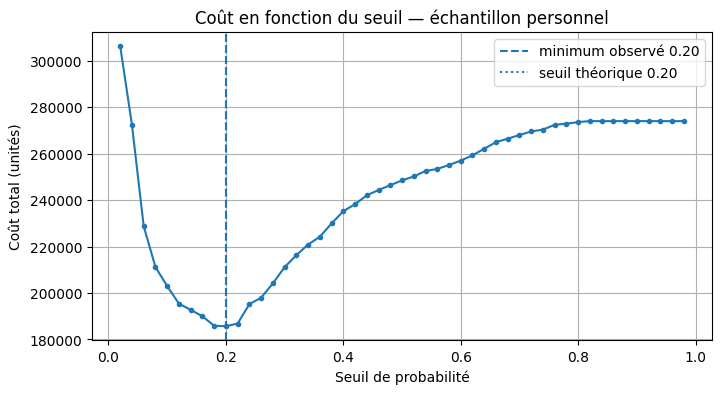

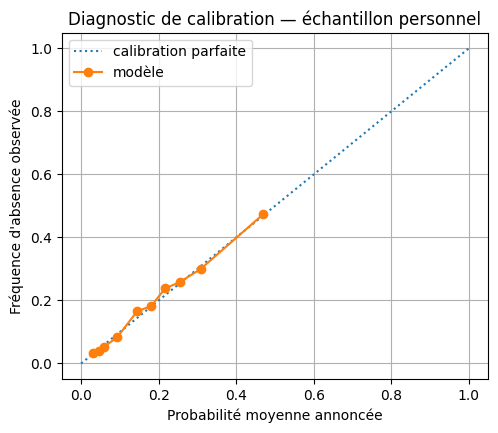

,seuil,coût
9,0.20,185700
8,0.18,185900
10,0.22,186850
7,0.16,189975
6,0.14,192775
11,0.24,195225
5,0.12,195400
12,0.26,197975
4,0.10,202975
13,0.28,204125


Seuil minimisant le coût observé : 0.20
Coût à ce seuil : 185700
Seuil théorique des coûts : 0.20
Coût au seuil 0,50 : 248500
Au seuil 0,50, l'exactitude vaut 82.56 %, mais la décision coûte 248500 unités. Sur mon échantillon, le coût minimal est 185700 unités au seuil 0.20, contre le seuil théorique 0.20. L'écart moyen de calibration par bac est 0.009 (Brier=0.130) : la formule suppose des probabilités calibrées ; ce diagnostic ne prouve pas une calibration parfaite.
Important : pour le fichier final, le pipeline utilise 0.18, seuil appris par validation croisée sur Xtr, et non le seuil optimisé sur l'échantillon de contrôle personnel.
  ok        un seuil écrit entre 0 et 1
  ok        deux coûts, des entiers positifs
  ok        l’écart est argumenté


In [59]:
# Le seuil de la formule (0,20) suppose des probabilités calibrées.
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

seuils_cout = np.round(np.arange(0.02, 1.00, 0.02), 2)
couts_mesures = [
    int(cout((p >= seuil).astype(int), verite=yval_perso))
    for seuil in seuils_cout
]
indice_min = int(np.argmin(couts_mesures))
mon_seuil_choisi = float(seuils_cout[indice_min])
cout_a_mon_seuil = int(couts_mesures[indice_min])

# Comparaison au seuil standard : strictement proba > 0,50, comme le demande l'énoncé.
cout_du_seuil_par_defaut = int(
    cout((p > 0.50).astype(int), verite=yval_perso)
)
seuil_formule = COUT_FP / (COUT_FP + COUT_FN)
exactitude_05 = float(100 * ((p > 0.50).astype(int) == y_vrai).mean())

# Diagnostic de calibration : compare la probabilité moyenne à la fréquence observée par bac.
taux_observe, proba_moyenne = calibration_curve(
    y_vrai, p, n_bins=10, strategy="quantile"
)
ecart_calibration = float(np.mean(np.abs(taux_observe - proba_moyenne)))
brier = float(brier_score_loss(y_vrai, p))

ecart_metrique_cout = (
    f"Au seuil 0,50, l'exactitude vaut {exactitude_05:.2f} %, mais la décision coûte "
    f"{cout_du_seuil_par_defaut} unités. Sur mon échantillon, le coût minimal est "
    f"{cout_a_mon_seuil} unités au seuil {mon_seuil_choisi:.2f}, contre le seuil théorique "
    f"{seuil_formule:.2f}. L'écart moyen de calibration par bac est {ecart_calibration:.3f} "
    f"(Brier={brier:.3f}) : la formule suppose des probabilités calibrées ; ce diagnostic "
    "ne prouve pas une calibration parfaite."
)

plt.figure(figsize=(8, 4))
plt.plot(seuils_cout, couts_mesures, marker="o", markersize=3)
plt.axvline(mon_seuil_choisi, linestyle="--", label=f"minimum observé {mon_seuil_choisi:.2f}")
plt.axvline(seuil_formule, linestyle=":", label=f"seuil théorique {seuil_formule:.2f}")
plt.xlabel("Seuil de probabilité")
plt.ylabel("Coût total (unités)")
plt.title("Coût en fonction du seuil — échantillon personnel")
plt.legend()
plt.grid(True)
plt.show()

# Courbe de fiabilité : une probabilité moyenne de 0,30 devrait correspondre
# à environ 30 % d'absences observées si le modèle est bien calibré.
plt.figure(figsize=(5.5, 4.5))
plt.plot([0, 1], [0, 1], linestyle=":", label="calibration parfaite")
plt.plot(proba_moyenne, taux_observe, marker="o", label="modèle")
plt.xlabel("Probabilité moyenne annoncée")
plt.ylabel("Fréquence d'absence observée")
plt.title("Diagnostic de calibration — échantillon personnel")
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame({
    "seuil": seuils_cout,
    "coût": couts_mesures
}).sort_values("coût").head(10))
print(f"Seuil minimisant le coût observé : {mon_seuil_choisi:.2f}")
print(f"Coût à ce seuil : {cout_a_mon_seuil}")
print(f"Seuil théorique des coûts : {seuil_formule:.2f}")
print(f"Coût au seuil 0,50 : {cout_du_seuil_par_defaut}")
print(ecart_metrique_cout)
print(
    f"Important : pour le fichier final, le pipeline utilise {seuil_deploiement:.2f}, "
    "seuil appris par validation croisée sur Xtr, et non le seuil optimisé sur l'échantillon "
    "de contrôle personnel."
)

controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil_choisi < 1,
         'un seuil entre 0 et 1')
controle('deux coûts, des entiers positifs',
         lambda: cout_a_mon_seuil >= 0 and cout_du_seuil_par_defaut >= 0
                 and int(cout_a_mon_seuil) == cout_a_mon_seuil,
         'le coût est un entier, en unités de coût')
controle('l’écart est argumenté', lambda: len(ecart_metrique_cout) > 40,
         'chiffrez l’écart, et nommez les deux métriques comparées')

### Question 12 — Les deux classements  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le classement affiché se fait sur l'**exactitude** ; le cours vient de montrer que la décision
se paie en **coût**. Les deux classements ne désignent donc pas la même tête.

**Consigne.**
  1. prenez **deux stratégies** au moins sur votre échantillon (par exemple *n'alerte jamais*, et le
     modèle à deux seuils différents) ;
  2. classez-les deux fois, du meilleur au moins bon : par **exactitude**, puis par **coût** ;
  3. dites si la tête change, et ce que cela coûte de se fier à la métrique affichée.

**Livrables.** `classement_exactitude` · `classement_cout` · `tete_change`.

**Critère de réussite.** Deux stratégies suffisent : ce qui compte est que les deux classements
soient **mesurés sur la même population**.

*≈ 15 min.*


In [60]:
# Toutes les stratégies sont mesurées sur exactement le même échantillon personnel.
verite_perso = np.asarray(yval_perso, dtype=int)
probas = np.asarray(proba_perso, dtype=float)

strategies = {
    "Ne jamais alerter": np.zeros(len(verite_perso), dtype=int),
    "Modèle — seuil 0,20": (probas >= 0.20).astype(int),
    "Modèle — seuil 0,50": (probas > 0.50).astype(int),
    f"Modèle — seuil choisi {mon_seuil_choisi:.2f}":
        (probas >= mon_seuil_choisi).astype(int)
}
mesures_strategies = []
for nom, decisions in strategies.items():
    mesures_strategies.append({
        "stratégie": nom,
        "exactitude (%)": float(100 * (decisions == verite_perso).mean()),
        "coût": int(cout(decisions, verite=yval_perso))
    })

classement_exactitude = sorted(
    [(m["stratégie"], round(m["exactitude (%)"], 2)) for m in mesures_strategies],
    key=lambda x: x[1], reverse=True
)
classement_cout = sorted(
    [(m["stratégie"], m["coût"]) for m in mesures_strategies],
    key=lambda x: x[1]
)

tete_exactitude = classement_exactitude[0][0]
tete_cout = classement_cout[0][0]
tete_change = (
    f"La tête {'change' if tete_exactitude != tete_cout else 'ne change pas'} : "
    f"l'exactitude classe en premier « {tete_exactitude} », tandis que le coût classe en "
    f"premier « {tete_cout} ». Se fier uniquement à l'exactitude peut faire choisir une "
    "stratégie plus coûteuse, car une absence manquée coûte quatre fois une fausse alerte."
)

display(pd.DataFrame(mesures_strategies))
print("Classement par exactitude :", classement_exactitude)
print("Classement par coût :", classement_cout)
print(tete_change)

controle('deux classements',
         lambda: len(classement_exactitude) >= 2 and len(classement_cout) >= 2,
         'deux stratégies au moins, classées deux fois')
controle('la réponse est argumentée', lambda: len(str(tete_change)) > 40,
         'dites si la tête change, et pourquoi')

,stratégie,exactitude (%),coût
0,Ne jamais alerter,81.721147,274000
1,"Modèle — seuil 0,20",67.258172,185700
2,"Modèle — seuil 0,50",82.561708,248500
3,Modèle — seuil choisi 0.20,67.258172,185700


Classement par exactitude : [('Modèle — seuil 0,50', 82.56), ('Ne jamais alerter', 81.72), ('Modèle — seuil 0,20', 67.26), ('Modèle — seuil choisi 0.20', 67.26)]
Classement par coût : [('Modèle — seuil 0,20', 185700), ('Modèle — seuil choisi 0.20', 185700), ('Modèle — seuil 0,50', 248500), ('Ne jamais alerter', 274000)]
La tête change : l'exactitude classe en premier « Modèle — seuil 0,50 », tandis que le coût classe en premier « Modèle — seuil 0,20 ». Se fier uniquement à l'exactitude peut faire choisir une stratégie plus coûteuse, car une absence manquée coûte quatre fois une fausse alerte.
  ok        deux classements
  ok        la réponse est argumentée


## Ce qu’on rend, et pourquoi ce format

**Trois tableaux**, comme au devoir 1 :

- **le tableau à quatre colonnes** — modèle · validation · affiché · écart — et vos trois phrases ;
- **le journal de nettoyage** — une ligne par décision : la décision, le choix fait, l’effet mesuré ;
- **le tableau d’essais** — une ligne par changement, avec l’attendu (un signe et une raison) et le
  mesuré.

Les **constats chiffrés** et les **hypothèses de features** appartiennent au **devoir 1**. Les
questions d’ici portent sur les baselines, le nettoyage et la mesure. Les tableaux qui les
portent sont ceux-ci. **Vos métriques, vos aires et votre seuil** (Q10, Q11) se lisent dans les cellules qui
les produisent.

La cellule qui suit affiche **les trois tableaux** remplis automatiquement, tels que vous les rendez.


In [61]:
print("TABLEAU DES ESSAIS")
display(pd.DataFrame(ESSAIS))
print("JOURNAL DE NETTOYAGE")
display(pd.DataFrame(JOURNAL))
print("TABLEAU À QUATRE COLONNES")
display(mon_tableau)
print("CONTRÔLES")
display(pd.DataFrame(VERIFICATIONS))

print("\nFICHIER DE SOUMISSION")
print(CHEMIN_SOUMISSION)
print("Dimensions :", soumission.shape)
print("Seuil utilisé pour les prédictions finales :", seuil_deploiement)

TABLEAU DES ESSAIS


""


JOURNAL DE NETTOYAGE


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Écarter les colonnes identifiées comme constan...,Une variable constante ne distingue pas les li...,0.01,non
1,Code non documenté,Garder code_assurance en signalant que les mod...,Le dictionnaire disponible ne définit pas tout...,-0.01,non
2,Valeurs impossibles,Retirer les 46 lignes dont age est négatif de ...,Un âge négatif ne correspond pas à une mesure ...,-0.00,non
3,Doublons,Retirer les 0 doublons exacts hors identifiant...,Une même observation répétée peut donner un po...,0.00,non


TABLEAU À QUATRE COLONNES


,modèle,validation,affiché,écart
0,Réponse constante,81.75,NaN,NaN
1,Règle du délai (> 30 jours),79.92,NaN,NaN
2,Modèle du cours — HistGradientBoosting,82.51,81.81,0.7
3,Régression logistique,82.21,NaN,NaN


CONTRÔLES


,contrôle,tient
0,les données sont chargées,True
1,la table de travail est construite,True
2,"le découpage est fait, le modèle ajusté",True
3,les baselines sont mesurées,True
4,votre échantillon personnel est prêt,True
5,le pipeline tourne sur une table brute,True
6,le fichier est écrit,True
7,la règle est écrite,True
8,une exactitude en pourcentage,True
9,un écart exprimé en erreurs-types,True



FICHIER DE SOUMISSION
/kaggle/working/submission.csv
Dimensions : (63721, 2)
Seuil utilisé pour les prédictions finales : 0.18


## Rendre le travail

1. **Exécutez tout** le carnet (`Run All`), pour que les tableaux soient remplis.
2. **Déposez** ce carnet dans votre dépôt GitHub personnel. Mettez **avec** lui votre déclaration d’usage de
   l’IA, dans le **même commit** :
   - téléchargez le modèle **`DECLARATION_modele.md`** depuis le **dépôt du cours** ;
   - recopiez-le dans votre dépôt sous le nom **`declaration_DM2.md`** ;
   - remplissez-le : les deux scores, ce que vous avez produit seul, ce que vous avez fait
     avec un assistant, et ce que vous ne sauriez pas expliquer.
3. Vérifiez que le lien de votre dépôt est bien à jour dans le formulaire de la classe.

> Un travail non déposé n’existe pas.
